# Exercise 4 — The known RV giants

*Covers notebooks 01–04. Difficulty: ★★★☆☆*

Radial-velocity surveys have found dozens of cold giants around bright stars within 20 pc. Which of them could the ESC image in reflected light within a day?

In [1]:
import warnings
import numpy as np
import astropy.units as u
import matplotlib.pyplot as plt
import esc_etc
from esc_etc import Simulation, use_lazuli_style

use_lazuli_style()
warnings.filterwarnings("ignore", module="synphot")

def frame_for(sim, max_frame=1000 * u.s):
    """Frame time to use: max_frame, or half the saturation time if that is shorter."""
    return min(u.Quantity(max_frame, u.s), 0.5 * sim.saturation_time())


def hours_to_snr(sim, snr=5, max_frame=1000 * u.s):
    """Integration time (hours) to reach snr with the current configuration; NaN above the speckle plateau."""
    return sim.get_int_time_for_snr(snr, frame_for(sim, max_frame))["int_time_continuous"][0].to_value(u.hr)

### 4.1 — The sample

Load `12_nearby_rv_giants.csv` (RV planets with $0.3 < M \sin i < 15\,M_J$, $a > 1$ AU, $d < 20$ pc,
host $V < 7$, from the NASA Exoplanet Archive). For each planet compute the maximum separation
$a/d$ in arcsec and the reflected-light contrast at quadrature, $C = A_g (R_p/a)^2 / \pi$ with
$A_g = 0.5$ and the archive radius (1 $R_J$ where missing).

In [2]:
import pandas as pd
from pathlib import Path
csv = next(d / "data" / "12_nearby_rv_giants.csv" for d in Path.cwd().parents if (d / "data" / "12_nearby_rv_giants.csv").exists())
df = pd.read_csv(csv)
print(len(df), "planets")
df[["pl_name", "pl_orbsmax", "pl_bmassj", "pl_radj", "sy_dist", "sy_vmag", "st_spectype"]].head()

25 planets


,pl_name,pl_orbsmax,pl_bmassj,pl_radj,sy_dist,sy_vmag,st_spectype
0,55 Cnc d,5.600,3.878,1.16,12.5855,5.95084,G8 V
1,HD 10647 b,2.015,0.940,1.23,17.3357,5.52000,F9 V
2,HD 62509 b,1.640,2.300,1.19,10.3400,1.12512,K0IIIvar
3,HD 160691 b,1.500,4.300,NaN,15.5981,5.12000,G3 IV-V
4,7 CMa b,1.758,1.850,1.20,19.8101,3.95000,K1III(+M)


In [3]:
from astropy.constants import R_jup, au
R_p = df.pl_radj.fillna(1.0).values * R_jup
a = df.pl_orbsmax.values * au
df["sep_arcsec"] = df.pl_orbsmax / df.sy_dist                     # AU / pc = arcsec
df["contrast"] = (0.5 / np.pi * (R_p / a) ** 2).decompose().value
print(f"contrast {df.contrast.min():.1e} to {df.contrast.max():.1e}; separation {df.sep_arcsec.min():.2f} to {df.sep_arcsec.max():.2f} arcsec")

contrast 1.1e-10 to 3.3e-08; separation 0.07 to 4.33 arcsec


### 4.2 — A cell with a bug

The cell below computes the time to S/N 5 for every planet. It runs, but the numbers are absurd:
every planet is detected in seconds. Find the bug, fix it, and keep going.

In [4]:
sim = Simulation.from_default(filter="R3", hoststarmag=5.0, hoststar_band="johnson_v", planetdeltamag=20, contrast=1e-8, ppgain=10, separation=0.4)
edge = sim.coronagraph._lamD.max() * (sim.coronagraph.primary_filter / sim.coronagraph.diameter_primary).to_value(u.arcsec, equivalencies=u.dimensionless_angles())

def time_to_snr5(V, contrast, sep, ppgain=10):
    if sep > edge:
        return np.nan                                             # beyond the tabulated dark hole
    sim.update(scene__star__mag=V, scene__planet__deltamag=-2.5 * np.log10(contrast),   # fixed: the sign; delta mag is positive (planet fainter)
               coronagraph__separation=sep, coronagraph__ppgain=ppgain)
    h = hours_to_snr(sim)
    sim.reset()
    return h

df["t_hr"] = [time_to_snr5(r.sy_vmag, r.contrast, r.sep_arcsec) for r in df.itertuples()]
print(df[["pl_name", "sy_vmag", "sep_arcsec", "contrast", "t_hr"]].sort_values("t_hr").head(8).to_string(index=False))

    pl_name  sy_vmag  sep_arcsec     contrast     t_hr
 HD 62509 b  1.12512    0.158607 1.913773e-08 0.004236
  gam Cep b  3.23006    0.140260 1.165380e-08 0.101864
    7 CMa b  3.95000    0.088743 1.693593e-08 0.339259
    7 CMa c  3.95000    0.108682 1.205701e-08 0.378644
HD 147513 b  5.37000    0.102300 3.104960e-08 0.650783
 HD 27442 b  4.44000    0.069566 3.294305e-08 0.667234
  ups And d  4.09565    0.187483 7.089979e-09 0.730753
   47 UMa b  5.03352    0.152210 1.147650e-08 0.901383


### 4.3 — Inside the working angle

Add a column `in_wa` for planets between the 50 %-throughput IWA and the table edge. How many
planets reach S/N 5 within a day *and* sit in the working angle at ppgain 10? And at ppgain 30?

In [5]:
cg = sim.coronagraph
lamD = (cg.primary_filter / cg.diameter_primary).to_value(u.arcsec, equivalencies=u.dimensionless_angles())
IWA = (cg._lamD * lamD)[np.argmax(cg._throughput >= 0.5 * cg._throughput.max())]
df["in_wa"] = (df.sep_arcsec >= IWA) & (df.sep_arcsec <= edge)
df["t_hr_pp30"] = [time_to_snr5(r.sy_vmag, r.contrast, r.sep_arcsec, 30) for r in df.itertuples()]
for col in ("t_hr", "t_hr_pp30"):
    ok = df.in_wa & (df[col] <= 24)
    print(f"{col}: {ok.sum()} planets in a day inside the working angle -> {', '.join(df[ok].sort_values(col).pl_name)}")
print(f"beyond the table edge ({edge:.2f}\"): {', '.join(df[df.sep_arcsec > edge].pl_name)}")

t_hr: 1 planets in a day inside the working angle -> ups And d
t_hr_pp30: 5 planets in a day inside the working angle -> ups And d, 47 UMa c, HD 219134 h, HD 39091 b, HD 190360 b
beyond the table edge (0.91"): eps Ind A b, HD 115404 A c, eps Eri b, HD 145675 c


### 4.4 — The picture

Plot contrast against separation for all planets, coloured by the time to S/N 5 (log scale), with
the IWA, the table edge and the contrast floor marked, and the names on the points.

/var/folders/0t/mnkwbhz90sv50nypf2rcl8cr0000gp/T/ipykernel_42478/2580365935.py:3: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  ax.axvspan(0.03, IWA, color="0.92", lw=0); ax.axvspan(edge, 6, color="0.95", hatch="//", edgecolor="0.8", lw=0)


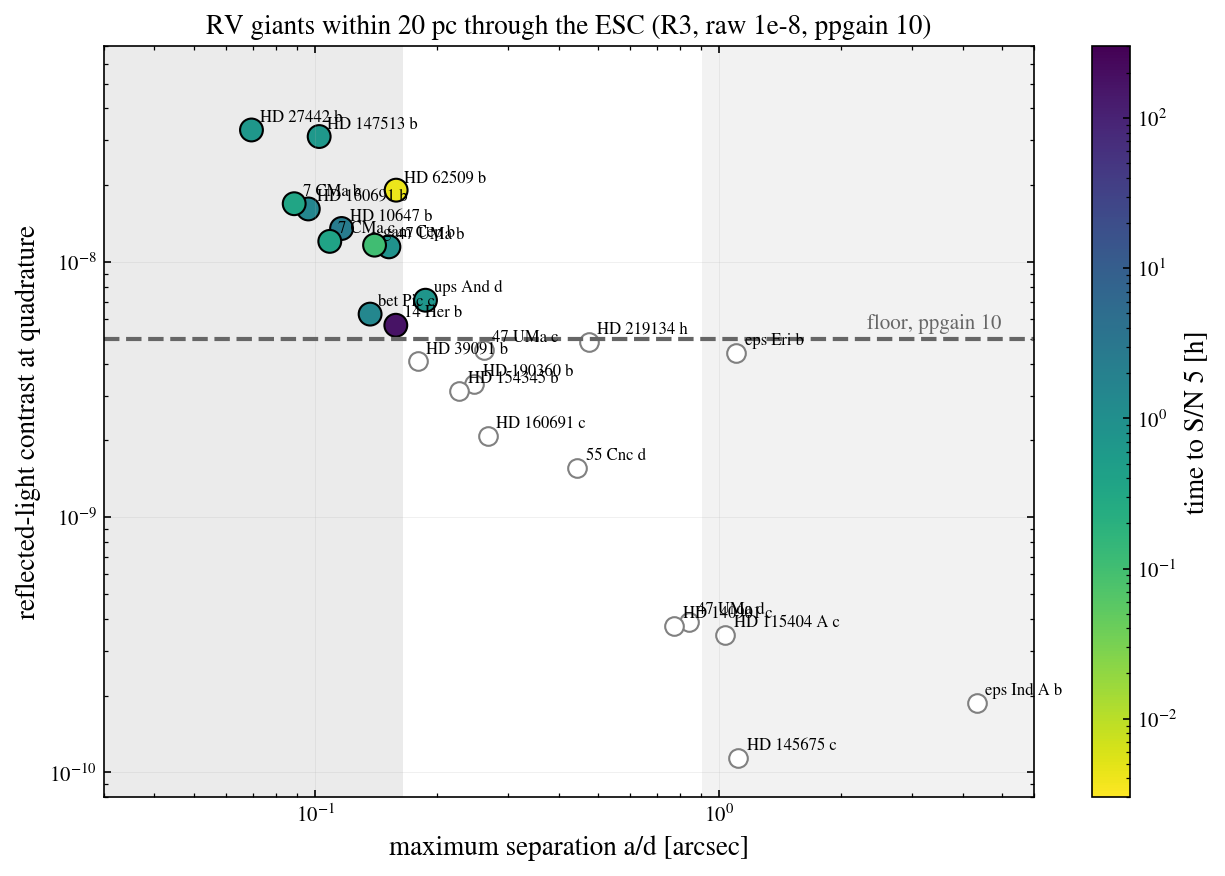

In [6]:
from matplotlib.colors import LogNorm
fig, ax = plt.subplots(figsize=(10, 6.5))
ax.axvspan(0.03, IWA, color="0.92", lw=0); ax.axvspan(edge, 6, color="0.95", hatch="//", edgecolor="0.8", lw=0)
ax.axhline(5e-8 / 10, color="0.4", ls="--"); ax.text(5, 5.5e-9, "floor, ppgain 10", ha="right", color="0.4")
good = df.t_hr.notna()
sc = ax.scatter(df.sep_arcsec[good], df.contrast[good], c=df.t_hr[good], norm=LogNorm(0.003, 300), cmap="viridis_r", s=120, edgecolor="k")
ax.scatter(df.sep_arcsec[~good], df.contrast[~good], facecolor="white", edgecolor="0.5", s=80)
for r in df.itertuples():
    ax.annotate(r.pl_name, (r.sep_arcsec, r.contrast), xytext=(4, 4), textcoords="offset points", fontsize=8)
fig.colorbar(sc, ax=ax, label="time to S/N 5 [h]")
ax.set(xscale="log", yscale="log", xlim=(0.03, 6), ylim=(8e-11, 7e-8), xlabel="maximum separation a/d [arcsec]", ylabel="reflected-light contrast at quadrature",
       title="RV giants within 20 pc through the ESC (R3, raw 1e-8, ppgain 10)")
plt.show()

> 🤖 **Ask Jupyter AI:** *The separations above are maximum elongations for circular orbits. For the three planets with eccentricity above 0.3 in the table, compute the range of projected separations over the orbit (ignoring inclination) and say whether they ever leave the working angle.*
>
> Then ask it to draft the observing-calendar extension: separation and phase angle on real dates, from an astrometric orbit.

***
## Share-back and feedback

Bring back **one plot and one number** to the share-back board, and the observing decision you draw
from them.

> 🤖 **Ask Jupyter AI:** *Draft a GitHub issue for schmidt-observatories/esc-etc describing one thing I
> found missing, confusing or wrong in this exercise, with a minimal code example.*